<a href="https://colab.research.google.com/github/TharikaBD/Tharika-Unlox/blob/main/Tharika_LiReg_car_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/uncleaned_used_cars_eda.csv")

In [3]:
df.head()

,car_id,brand,model,year,price_inr,km_driven,fuel_type,transmission,owner_type,mileage_kmpl,engine_cc,city,insurance_valid,seller_rating,listed_date
0,CAR001,maruti,Baleno,2009,236000.0,13300,petrol,manual,1st,12.9,1000.0,hyderabad,Yes,3.1,02-02-26
1,CAR002,MARUTI,i20,2010,292000.0,17600,Diesel,Automatic,Second,13.8,1200.0,Hyd,Yes,3.2,03-03-26
2,CAR003,Hyundai,Creta,2011,348000.0,21900,diesel,Auto,2nd,14.7,1400.0,Bangalore,Yes,3.3,04-04-26
3,CAR004,hyundai,Nexon,2012,404000.0,26200,CNG,AUTOMATIC,Third,15.6,1600.0,Bengaluru,NO,3.4,05-05-26
4,CAR005,Tata,XUV300,2013,460000.0,30500,Electric,Manual,3rd,16.5,1800.0,Mumbai,Yes,3.5,06-06-26


In [4]:
df.tail()

,car_id,brand,model,year,price_inr,km_driven,fuel_type,transmission,owner_type,mileage_kmpl,engine_cc,city,insurance_valid,seller_rating,listed_date
118,CAR119,Toyta,Altroz,2008,1261000.0,120800,Petrol,AUTOMATIC,3rd,20.1,2200.0,New Delhi,Yes,4.4,12-12-26
119,CAR120,Maruti,Swift,2009,189000.0,125100,petrol,Manual,First,12.0,800.0,Hyderabad,NO,4.5,13-01-26
120,CAR012,Maruti,i20,2020,789000.0,60600,Electric,Automatic,First,13.8,1600.0,Hyd,NO,4.2,13-01-26
121,CAR038,NaN,Innova,2012,865000.0,39100,diesel,Auto,Second,19.2,2000.0,Delhi,Yes,4.7,12-03-26
122,CAR075,Hyundai,XUV300,2015,366000.0,64900,Electric,Manual,2nd,16.5,1400.0,Mumbai,Yes,4.2,31/02/2025


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   car_id           123 non-null    object 
 1   brand            116 non-null    object 
 2   model            123 non-null    object 
 3   year             123 non-null    object 
 4   price_inr        118 non-null    float64
 5   km_driven        123 non-null    object 
 6   fuel_type        123 non-null    object 
 7   transmission     120 non-null    object 
 8   owner_type       123 non-null    object 
 9   mileage_kmpl     118 non-null    float64
 10  engine_cc        119 non-null    float64
 11  city             123 non-null    object 
 12  insurance_valid  123 non-null    object 
 13  seller_rating    123 non-null    float64
 14  listed_date      123 non-null    object 
dtypes: float64(4), object(11)
memory usage: 14.5+ KB


In [6]:
df.describe()

,price_inr,mileage_kmpl,engine_cc,seller_rating
count,1.180000e+02,118.000000,119.000000,123.000000
mean,7.984492e+05,16.118644,1507.563025,4.204065
std,8.676712e+05,2.613769,456.805352,1.091127
min,1.890000e+05,12.000000,800.000000,3.000000
25%,4.532500e+05,13.800000,1200.000000,3.600000
50%,7.285000e+05,16.500000,1600.000000,4.100000
75%,9.852500e+05,18.300000,1900.000000,4.550000
max,9.500000e+06,20.100000,2200.000000,8.700000


In [7]:
df.isnull().sum()

,0
car_id,0
brand,7
model,0
year,0
price_inr,5
km_driven,0
fuel_type,0
transmission,3
owner_type,0
mileage_kmpl,5


In [8]:
df=df.dropna()

In [9]:
df.isnull().sum()

,0
car_id,0
brand,0
model,0
year,0
price_inr,0
km_driven,0
fuel_type,0
transmission,0
owner_type,0
mileage_kmpl,0


In [10]:
df.duplicated().sum()

np.int64(2)

In [11]:
df.drop_duplicates(inplace=True)

In [12]:
df.duplicated().sum()

np.int64(0)

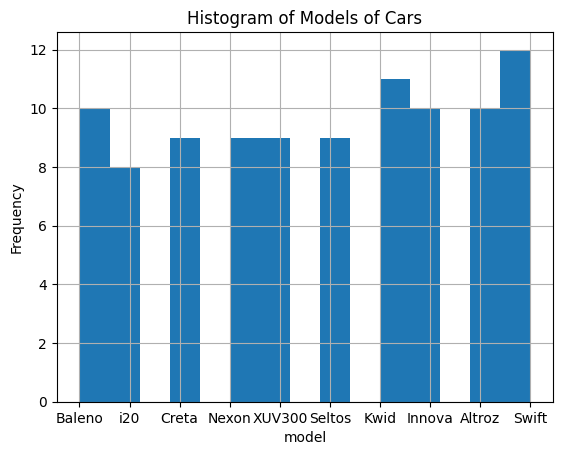

In [13]:
#Univariate analysis
df["model"].hist(bins = 15)
plt.title("Histogram of Models of Cars")
plt.xlabel("model")
plt.ylabel("Frequency")
plt.show()

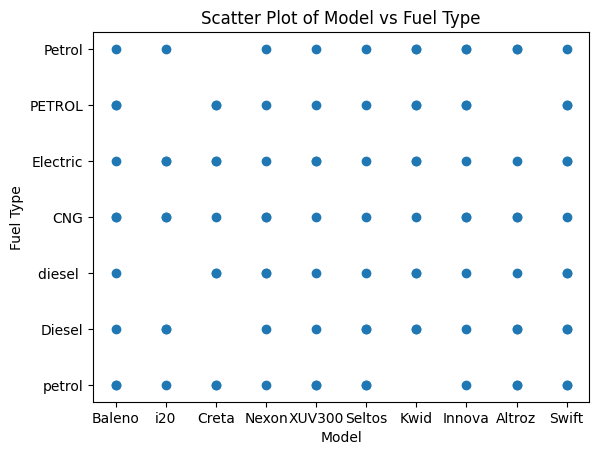

In [14]:
#Bivariate Analysis
plt.scatter(df["model"], df["fuel_type"])
plt.title("Scatter Plot of Model vs Fuel Type")
plt.xlabel("Model")
plt.ylabel("Fuel Type")
plt.show()

In [15]:
numeric_df=df.select_dtypes(include=["int64","float64"]).columns

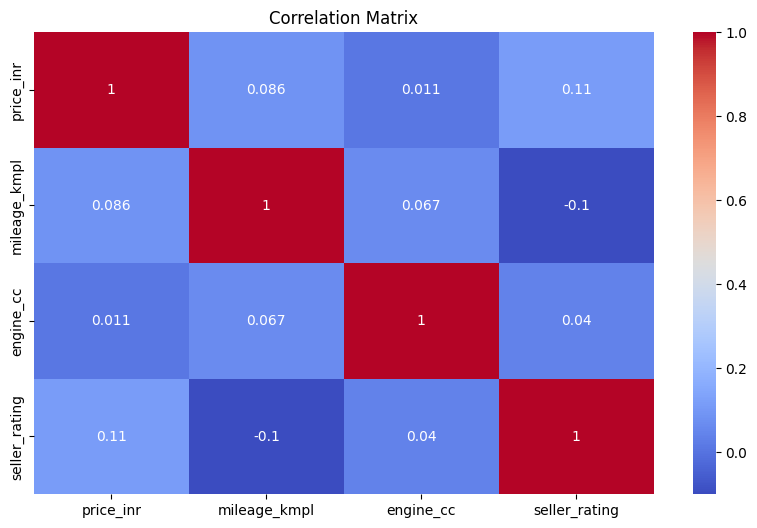

In [16]:
#Multivariate Analysis
plt.figure(figsize=(10,6))
sns.heatmap(df[numeric_df].corr(),annot=True,cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

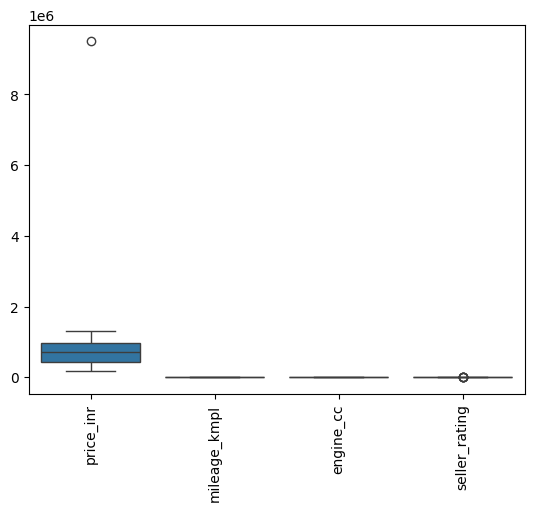

In [17]:
#Outlier detection
# Select only numeric columns directly as a DataFrame
numeric_data_for_boxplot = df.select_dtypes(include=np.number)
sns.boxplot(data=numeric_data_for_boxplot)
plt.xticks(rotation=90)
plt.show()

In [18]:
for col in numeric_df:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

In [19]:
print(df.shape)
df[numeric_df].describe().sum()

(91, 15)


,0
price_inr,4.564509e+06
mileage_kmpl,1.904297e+02
engine_cc,9.221224e+03
seller_rating,1.158894e+02


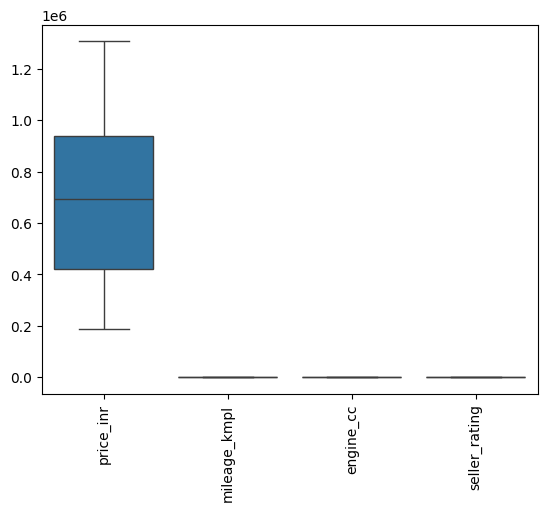

In [20]:
numeric_data_for_boxplot = df.select_dtypes(include=np.number)
sns.boxplot(data=numeric_data_for_boxplot)
plt.xticks(rotation=90)
plt.show()

In [28]:
from sklearn.preprocessing import LabelEncoder

for col in df.select_dtypes(include='object').columns:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 91 entries, 0 to 119
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   car_id           91 non-null     int64  
 1   brand            91 non-null     int64  
 2   model            91 non-null     int64  
 3   year             91 non-null     int64  
 4   price_inr        91 non-null     float64
 5   km_driven        91 non-null     int64  
 6   fuel_type        91 non-null     int64  
 7   transmission     91 non-null     int64  
 8   owner_type       91 non-null     int64  
 9   mileage_kmpl     91 non-null     float64
 10  engine_cc        91 non-null     float64
 11  city             91 non-null     int64  
 12  insurance_valid  91 non-null     int64  
 13  seller_rating    91 non-null     float64
 14  listed_date      91 non-null     int64  
dtypes: float64(4), int64(11)
memory usage: 11.4 KB


In [30]:
#Dividing variable into dependent[y] and independent[x]
X = df.drop(columns=["price_inr"])
y = df["price_inr"]

In [31]:
X.head()

,car_id,brand,model,year,km_driven,fuel_type,transmission,owner_type,mileage_kmpl,engine_cc,city,insurance_valid,seller_rating,listed_date
0,0,11,1,1,11,6,4,0,12.9,1000.0,9,1,3.1,4
1,1,2,9,2,15,1,2,4,13.8,1200.0,4,1,3.2,8
2,2,0,2,3,16,5,1,1,14.7,1400.0,0,1,3.3,12
3,3,10,5,4,17,0,0,5,15.6,1600.0,1,0,3.4,15
4,4,7,8,5,18,2,3,2,16.5,1800.0,6,1,3.5,18


In [32]:
y.head()

,price_inr
0,236000.0
1,292000.0
2,348000.0
3,404000.0
4,460000.0


In [33]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size =0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((72, 14), (19, 14), (72,), (19,))

In [34]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [41]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import mean_absolute_error

In [36]:
model= LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [37]:
y_pred= model.predict(X_test)
y_pred

array([672115.90298884, 756645.93171291, 617451.13638626, 743184.10889868,
       871553.84179902, 685212.91446132, 897024.53624494, 801514.58459773,
       876796.08327881, 699979.10102686, 735147.7909153 , 804447.71729905,
       728856.19148939, 678441.286487  , 691352.91672954, 757461.3794075 ,
       360166.05985806, 807228.26878841, 538494.37416735])

In [38]:
comparison=pd.DataFrame({"Actual":y_test,"Predicted":y_pred})
comparison.head(10)

,Actual,Predicted
52,451000.0,672115.902989
28,424000.0,756645.931713
72,254000.0,617451.136386
117,1268000.0,743184.108899
0,236000.0,871553.841799
33,704000.0,685212.914461
50,339000.0,897024.536245
86,912000.0,801514.584598
10,733000.0,876796.083279
57,668000.0,699979.101027


In [42]:
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print("Mean Squared Error:",mse)
print("Mean Absolute Error:",mae)
print("R2 Score:",r2)

Mean Squared Error: 118075110072.28685
Mean Absolute Error: 281093.17665506544
R2 Score: -0.01684585774958869


In [47]:
#Unseen data set
new_data = pd.DataFrame({
    'car_id': [0], # Placeholder for car_id
    'brand': [5],
    'model': [99],
    'year': [3],
    'km_driven': [3], # Placeholder for km_driven
    'fuel_type': [6],
    'transmission': [7], # Placeholder for transmission
    'owner_type': [0], # Placeholder for owner_type
    'mileage_kmpl': [0.0], # Placeholder for mileage_kmpl
    'engine_cc': [0.0], # Placeholder for engine_cc
    'city': [6], # Placeholder for city
    'insurance_valid': [23], # Placeholder for insurance_valid
    'seller_rating': [0.0], # Placeholder for seller_rating
    'listed_date': [0] # Placeholder for listed_date
})
new_data_scaled=scaler.transform(new_data)
predicted_performance_index = model.predict(new_data_scaled)
print("Predicted Performance Index:", predicted_performance_index[0])

Predicted Performance Index: -1569583.70090413


In [48]:
print("coeffiecents:",model.coef_)
print("intercept:",model.intercept_)

coeffiecents: [ 18719.67422269  24857.69721953 -76104.62822912 -47087.81569459
  43023.49780918  -3905.29815838  57136.34362612  46331.93303423
 -11856.87461639  81388.15748923  10180.5571847    3098.69816294
 -20928.39557588 -40413.54183648]
intercept: 691111.1111111111


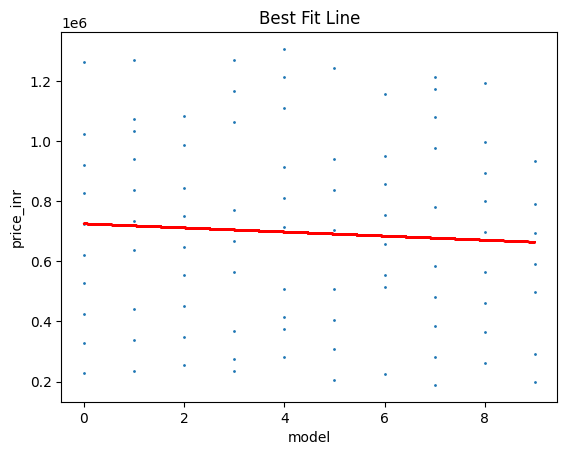

In [49]:
#call best fit line
plt.scatter(df['model'],df['price_inr'],1)
m, c = np.polyfit(df['model'], df['price_inr'], 1)
plt.plot(df['model'], m*df['model'] + c, color='red')
plt.xlabel('model')
plt.ylabel('price_inr')
plt.title('Best Fit Line')
plt.show()